<a href="https://colab.research.google.com/github/Fortes04/MyRepo/blob/master/TCC_Previsao_Atrasos_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC — previsão de atraso na montagem de transformadores

**Objetivo:** executar o código fornecido do TCC, consultar as análises e exportar os resultados no Google Colab.

### Como usar

1. No Google Colab, abra este arquivo `.ipynb` e selecione **Ambiente de execução → Executar tudo**. Autorize a execução se o Colab solicitar.
2. Quando solicitado, selecione **os dois arquivos juntos**: `Base_Modelo_V2.xlsx` e `Controle - Transformadores.xlsx`. Eles também podem ser enviados antes pelo ícone de pasta.
3. Acompanhe as células: preparação dos dados, análises descritivas, regressão, classificação, importância das variáveis e teste retrospectivo da ferramenta.
4. Ao final, o notebook reúne os resultados e gráficos em `resultados_TCC.zip` para baixar pelo painel de arquivos ou pela última célula.

**Tempo:** a pesquisa de hiperparâmetros treina muitos modelos; a duração depende dos recursos disponíveis no Colab. Os resultados podem variar com as versões das bibliotecas. A semente 42 é mantida e as versões e identificadores das planilhas são registradas.

**Escopo:** esta é uma reprodução do código recebido, preservando seus cálculos; a seção da ferramenta aplica um teste retrospectivo a ordens históricas de março a julho de 2026. A planilha exportada não é uma previsão automática para novas ordens.

Os arquivos de entrada e alguns resultados contêm identificadores da empresa, como ordens e números de série.


## 1. Preparar o ambiente

A célula verifica as dependências e mostra as versões em uso. Por padrão, utiliza as versões já disponíveis no Colab. A execução mencionada no retorno anterior usou `scikit-learn 1.5.1`, mas a versão que produziu todos os números do documento ainda precisa ser confirmada. Para tentar reproduzir aquela execução, altere o valor da variável abaixo **antes de rodar as demais células**. A instalação depende da compatibilidade com a versão de Python do ambiente.


In [3]:
# Deixe None para usar a versão instalada; opcionalmente informe "1.5.1".
VERSAO_SCIKIT_LEARN = None

import sys, subprocess, importlib.util, importlib.metadata

pacotes = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "scipy": "scipy", "sklearn": "scikit-learn", "openpyxl": "openpyxl",
}
faltantes = [pip for modulo, pip in pacotes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando dependências ausentes:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])

if VERSAO_SCIKIT_LEARN:
    instalada = importlib.metadata.version("scikit-learn")
    if instalada != VERSAO_SCIKIT_LEARN:
        if "sklearn" in sys.modules:
            raise RuntimeError("Reinicie o ambiente de execução antes de alterar a versão do scikit-learn.")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               f"scikit-learn=={VERSAO_SCIKIT_LEARN}"])

versoes_ambiente = {"python": sys.version}
for pacote in pacotes.values():
    versoes_ambiente[pacote] = importlib.metadata.version(pacote)
print("Ambiente da execução:")
for pacote, versao in versoes_ambiente.items():
    print(f"  {pacote}: {versao}")


Ambiente da execução:
  python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
  numpy: 2.4.6
  pandas: 2.2.3
  matplotlib: 3.10.0
  scipy: 1.16.3
  scikit-learn: 1.6.1
  openpyxl: 3.1.5


## 2. Carregar as duas planilhas

Selecione os arquivos com os nomes indicados. Se já estiverem no ambiente, esta etapa prosseguirá sem solicitar novo envio.


In [4]:
from pathlib import Path

nomes_necessarios = ["Base_Modelo_V2.xlsx", "Controle - Transformadores.xlsx"]
pastas_de_busca = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive")]
def arquivos_ausentes():
    return [nome for nome in nomes_necessarios
            if not any((pasta / nome).is_file() for pasta in pastas_de_busca)]

faltantes = arquivos_ausentes()
if faltantes:
    print("Selecione os arquivos:", ", ".join(faltantes))
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError("Coloque as duas planilhas na pasta atual e execute novamente: "
                                + ", ".join(faltantes)) from exc
    files.upload()
    faltantes = arquivos_ausentes()
    if faltantes:
        raise FileNotFoundError("Arquivo(s) não encontrado(s): " + ", ".join(faltantes)
                                + ". Confira os nomes e execute esta célula novamente.")
print("As duas planilhas estão disponíveis.")


As duas planilhas estão disponíveis.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Bibliotecas e configuração do estudo

Este e os próximos blocos contêm o código recebido, organizado em células. A lógica dos modelos e os critérios de cálculo foram preservados.


In [6]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.linear_model import ElasticNet, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_val_predict)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             median_absolute_error, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, brier_score_loss,
                             balanced_accuracy_score, matthews_corrcoef)

warnings.filterwarnings("ignore")
SEMENTE = 42
RES = {}

# -----------------------------------------------------------------------------
# 1. LOCALIZACAO DOS ARQUIVOS
# -----------------------------------------------------------------------------
NOME_BASE = "Base_Modelo_V2.xlsx"
NOME_CTRL = "Controle - Transformadores.xlsx"
# pastas onde os dois arquivos de entrada sao procurados, nesta ordem
PASTAS = [".", "/content", "/content/drive/MyDrive"]


def achar(nome):
    for pasta in PASTAS:
        caminho = os.path.join(pasta, nome)
        if os.path.exists(caminho):
            return caminho
    raise FileNotFoundError(
        f"Arquivo '{nome}' nao encontrado. Coloque-o na pasta do script.")


BASE = achar(NOME_BASE)
CTRL = achar(NOME_CTRL)
SAIDA = "/content" if os.path.isdir("/content") else "."


def linha(t):
    print("\n" + "=" * 78)
    print(t)
    print("=" * 78)


def virg(v, dec=1):
    return f"{v:.{dec}f}".replace(".", ",")


# -----------------------------------------------------------------------------
# 2. ESTILO VISUAL DOS GRAFICOS
# -----------------------------------------------------------------------------
disponiveis = {f.name for f in fm.fontManager.ttflist}
for preferida in ["Carlito", "Calibri", "Liberation Sans", "DejaVu Sans"]:
    if preferida in disponiveis:
        rcParams["font.family"] = preferida
        break

rcParams["axes.edgecolor"] = "#5A5A5A"
rcParams["axes.labelcolor"] = "#2B2B2B"
rcParams["text.color"] = "#2B2B2B"
rcParams["xtick.color"] = "#4A4A4A"
rcParams["ytick.color"] = "#4A4A4A"
rcParams["axes.linewidth"] = 0.9
rcParams["figure.dpi"] = 120
rcParams["savefig.dpi"] = 220
rcParams["savefig.facecolor"] = "white"

PASTEL = {"azul": "#A8C5DD", "verde": "#B5D3C2", "areia": "#E8D9B5",
          "terracota": "#E0B0A0", "lilas": "#C9BBD9", "cinza": "#D5D5D5"}
FORTE = {"azul": "#2A5C8A", "vermelho": "#B33A3A", "ambar": "#D9A441",
         "verde": "#3E7C59", "grafite": "#3A3A3A"}


def limpa(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid_axis:
        ax.grid(axis=grid_axis, color="#DDDDDD", linewidth=0.7, zorder=0)
        ax.set_axisbelow(True)


def titulo(ax, texto, sub=None):
    ax.set_title(texto.upper(), fontsize=11.5, fontweight="bold",
                 color="#1F1F1F", pad=16 if sub else 12, loc="left")
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=8.6,
                color="#6A6A6A", va="bottom", ha="left")


def eixo_br(ax, eixo="x", dec=0):
    """Numeros do eixo com virgula decimal (padrao brasileiro)."""
    def f(v, _):
        return f"{v:,.{dec}f}".replace(",", "@").replace(".", ",").replace("@", ".")
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(FuncFormatter(f))


def ticks_inteiros(ax, eixo="x", n=6):
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_locator(
        MaxNLocator(nbins=n, integer=True))


## 4. Preparar os dados e construir a cadeia

A unidade de análise é a ordem do transformador. Nesta etapa, as ordens de componentes são relacionadas ao produto pelo número de série. A saída de regressão é a diferença em dias entre o término real e o planejado; a classe positiva corresponde a atraso maior que zero.


In [7]:
# =============================================================================
# 3. LEITURA, SEPARACAO DO ITEM FERT E CONSTRUCAO DA CADEIA
# =============================================================================
# Saneamento declarado como constante
PESO_MINIMO = 10.0      # kg; abaixo disso e erro de cadastro

linha("3. LEITURA E SEPARACAO DO ITEM FERT")
cab = pd.read_excel(BASE, sheet_name="Cabecalho")
ope = pd.read_excel(BASE, sheet_name="Operacoes")

# Campos de data do cabecalho da ordem:
#   GSTRP = inicio planejado | GSTRI = inicio real
#   GLTRP = fim planejado    | GLTRI = fim real
for c in ["GSTRP", "GSTRI", "GLTRP", "GLTRI"]:
    cab[c] = pd.to_datetime(cab[c], errors="coerce")

# O item FERT (produto acabado) e o transformador. O texto do material
# distingue sem ambiguidade: as ordens de componente descrevem conjunto de
# caldeiraria, nucleo, enrolamento ou montagem da parte ativa.
cab["desc"] = cab["MATXT"].astype(str).str.upper()
cab["eh_fert"] = cab["desc"].str.startswith("TRANSFORMADOR")
fert = cab[cab["eh_fert"]].copy()
comp = cab[~cab["eh_fert"]].copy()

print(f"ordens de transformador (FERT): {len(fert)}")
print(f"ordens de componente:           {len(comp)}")
print(f"numeros de serie distintos:     {fert.NS.nunique()}")
print(f"apontamentos de operacao:       {len(ope)}")
RES["n_fert"] = int(len(fert))
RES["n_comp"] = int(len(comp))
RES["n_apont"] = int(len(ope))
RES["n_ordens_total"] = int(len(cab))

print("\nordens de componente por etapa do processo:")
print(comp.groupby("ETAPA").size().to_string())

fert["atraso"] = (fert["GLTRI"] - fert["GLTRP"]).dt.days
fert["lead_real"] = (fert["GLTRI"] - fert["GSTRI"]).dt.days
fert["lead_plan"] = (fert["GLTRP"] - fert["GSTRP"]).dt.days
fert = fert.dropna(subset=["atraso", "GSTRP"])

RES["atraso_media"] = float(fert.atraso.mean())
RES["atraso_mediana"] = float(fert.atraso.median())
RES["atraso_dp"] = float(fert.atraso.std())
RES["pct_atrasados"] = float((fert.atraso > 0).mean() * 100)
print(f"\natraso do transformador: media {fert.atraso.mean():.2f} dias | "
      f"mediana {fert.atraso.median():.0f} | desvio {fert.atraso.std():.2f} | "
      f"faixa {fert.atraso.min():.0f} a {fert.atraso.max():.0f}")
print(f"transformadores entregues com atraso: {(fert.atraso > 0).mean()*100:.1f}%")

# -----------------------------------------------------------------------------
# A cadeia como variavel do transformador
# -----------------------------------------------------------------------------
# Regra contra vazamento de informacao: o atraso REAL de um componente so pode
# ser usado se aquele componente ja houver sido concluido ANTES do inicio
# planejado da ordem do transformador. Caso contrario, no instante em que a
# ordem entra na programacao esse valor ainda nao existe.
linha("4. A CADEIA DE COMPONENTES COMO VARIAVEL DO TRANSFORMADOR")
comp["atraso_c"] = (comp["GLTRI"] - comp["GLTRP"]).dt.days
comp["lead_c"] = (comp["GLTRP"] - comp["GSTRP"]).dt.days

ETAPAS = {"CALDEIRARIA": "tanque", "CORTES_NUCLEO": "nucleo",
          "ENTRADA_BT": "bt", "ENTRADA_AT": "at", "ENTRADA_MPA": "mpa"}
ROTULO = {"tanque": "Tanque (caldeiraria)", "nucleo": "Núcleo",
          "bt": "Enrolamento BT", "at": "Enrolamento AT",
          "mpa": "Montagem da parte ativa"}
# rotulos curtos, distintos entre si, para os eixos dos graficos
CURTO = {"tanque": "TANQUE", "nucleo": "NÚCLEO", "bt": "ENROL. BT",
         "at": "ENROL. AT", "mpa": "PARTE ATIVA"}

base = fert[["NS", "CP", "AUFNR", "MATXT", "GSTRP", "GLTRP", "GLTRI",
             "atraso", "lead_plan", "lead_real", "mes"]].copy()

RES["sincronismo"] = {}
for etapa, nome in ETAPAS.items():
    d = comp[comp["ETAPA"] == etapa]
    g = d.groupby("NS").agg(fim_real=("GLTRI", "max"), fim_plan=("GLTRP", "max"),
                            atr=("atraso_c", "max"), lead=("lead_c", "max"))
    base = base.merge(g, on="NS", how="left")
    base[f"lead_plan_{nome}"] = base.pop("lead")
    base[f"folga_plan_{nome}"] = (base["GSTRP"] - base.pop("fim_plan")).dt.days
    fim_real = base.pop("fim_real")
    pronto = fim_real.notna() & (fim_real <= base["GSTRP"])
    base[f"atraso_{nome}"] = base.pop("atr").where(pronto)
    base[f"concluido_{nome}"] = pronto.astype(int)
    pct = pronto.mean() * 100
    RES["sincronismo"][nome] = float(pct)
    print(f"  {ROTULO[nome]:26s} pronto antes do início planejado: "
          f"{int(pronto.sum()):3d} de {len(base)} ({pct:4.1f}%)")

# -----------------------------------------------------------------------------
# Atributos construtivos do transformador
# -----------------------------------------------------------------------------
ctl = pd.read_excel(CTRL, sheet_name="BASE DE DADOS")
ctl["CP_i"] = pd.to_numeric(ctl["TRANSFORMADOR"], errors="coerce").astype("Int64")
ctl["kVA"] = (ctl["POTENCIA"].astype(str)
              .str.extract(r"([\d\.,]+)\s*kVA")[0]
              .str.replace(".", "", regex=False)
              .str.replace(",", ".", regex=False))
ctl["kVA"] = pd.to_numeric(ctl["kVA"], errors="coerce")
ctl = ctl.rename(columns={"TIPO DE MATERIAL": "TIPO_TANQUE", "PESO (IH09)": "PESO",
                          "Nº CAMADAS": "CAMADAS", "CAIXA DE BUCHA": "CAIXA_BUCHA",
                          "PLANO DE PINTURA": "PLANO_PINTURA"})
n_peso = int((ctl["PESO"] < PESO_MINIMO).sum())
ctl.loc[ctl["PESO"] < PESO_MINIMO, "PESO"] = np.nan
attrs = ctl[["CP_i", "TIPO_TANQUE", "kVA", "PESO", "CAIXA_BUCHA",
             "PLANO_PINTURA", "CAMADAS"]].drop_duplicates("CP_i")
base["CP_i"] = pd.to_numeric(base["CP"], errors="coerce").astype("Int64")
base = base.merge(attrs, on="CP_i", how="left")

# carga do sistema: transformadores planejados para a mesma semana
base["sem"] = base["GSTRP"].dt.to_period("W")
base = base.merge(base.groupby("sem").NS.count().rename("carga_semanal"),
                  on="sem", how="left")

print(f"\npesos invalidos tratados como ausentes: {n_peso}")
print(f"transformadores com atributos construtivos: "
      f"{int(base.TIPO_TANQUE.notna().sum())} de {len(base)}")

NUM = (["lead_plan", "kVA", "PESO", "CAMADAS", "carga_semanal"]
       + [f"lead_plan_{n}" for n in ETAPAS.values()]
       + [f"folga_plan_{n}" for n in ETAPAS.values()]
       + [f"atraso_{n}" for n in ETAPAS.values()]
       + [f"concluido_{n}" for n in ETAPAS.values()])
CAT = ["TIPO_TANQUE", "CAIXA_BUCHA", "PLANO_PINTURA"]
PRED = NUM + CAT

dm = base.dropna(subset=["atraso", "TIPO_TANQUE", "GSTRP"]).copy()
dm = dm[dm["TIPO_TANQUE"] != "SOLDADO"]
RES["n_amostra"] = int(len(dm))
RES["n_vars"] = len(PRED)
print(f"amostra de modelagem: {len(dm)} transformadores, {len(PRED)} variáveis")

X = dm[PRED]
y = dm["atraso"].astype(float)
yc = (y > 0).astype(int)
CORTE = pd.Timestamp("2026-03-01")
tr = dm.GSTRP < CORTE
te = dm.GSTRP >= CORTE



3. LEITURA E SEPARACAO DO ITEM FERT
ordens de transformador (FERT): 713
ordens de componente:           3586
numeros de serie distintos:     713
apontamentos de operacao:       36672

ordens de componente por etapa do processo:
ETAPA
CALDEIRARIA      723
CORTES_NUCLEO    670
ENTRADA_AT       731
ENTRADA_BT       736
ENTRADA_MPA      724
SAIDA_LINHA        2

atraso do transformador: media 9.10 dias | mediana 6 | desvio 17.60 | faixa -63 a 83
transformadores entregues com atraso: 63.0%

4. A CADEIA DE COMPONENTES COMO VARIAVEL DO TRANSFORMADOR
  Tanque (caldeiraria)       pronto antes do início planejado: 154 de 713 (21.6%)
  Núcleo                     pronto antes do início planejado: 570 de 713 (79.9%)
  Enrolamento BT             pronto antes do início planejado: 596 de 713 (83.6%)
  Enrolamento AT             pronto antes do início planejado: 447 de 713 (62.7%)
  Montagem da parte ativa    pronto antes do início planejado: 266 de 713 (37.3%)

pesos invalidos tratados como ausentes:

In [8]:
# Consulta das entradas efetivamente selecionadas antes da codificação categórica
try:
    from IPython.display import display
except ImportError:
    def display(valor):
        print(valor)
print("Variáveis de entrada originais:", len(PRED))
display(pd.DataFrame({"Variável": PRED,
                      "Natureza": ["numérica"] * len(NUM) + ["categórica"] * len(CAT)}))
print("Saída de regressão: GLTRI - GLTRP, em dias.")
print("Saída de classificação: 1 = atraso maior que zero; 0 = sem atraso.")
print(f"Amostra de modelagem: {len(dm)} | Treino antes de {CORTE.date()}: {int(tr.sum())} | Teste: {int(te.sum())}")


Variáveis de entrada originais: 28


,Variável,Natureza
0,lead_plan,numérica
1,kVA,numérica
2,PESO,numérica
3,CAMADAS,numérica
4,carga_semanal,numérica
5,lead_plan_tanque,numérica
6,lead_plan_nucleo,numérica
7,lead_plan_bt,numérica
8,lead_plan_at,numérica
9,lead_plan_mpa,numérica


Saída de regressão: GLTRI - GLTRP, em dias.
Saída de classificação: 1 = atraso maior que zero; 0 = sem atraso.
Amostra de modelagem: 619 | Treino antes de 2026-03-01: 376 | Teste: 243


## 5. Definição das análises descritivas

As funções abaixo preparam as tabelas e os gráficos. A célula seguinte as executa.


In [9]:
# =============================================================================
# 5. ANALISE DESCRITIVA
# =============================================================================
def descritiva_cadeia():
    """Atraso medio de cada etapa do processo, na ordem do fluxograma."""
    linha("5. ANALISE DESCRITIVA DA CADEIA")
    comp["atraso_c"] = (comp["GLTRI"] - comp["GLTRP"]).dt.days
    g = (comp.dropna(subset=["atraso_c"]).groupby("ETAPA")["atraso_c"]
         .agg(["count", "mean", "median"]))
    fer = pd.DataFrame({"count": [len(fert)], "mean": [fert.atraso.mean()],
                        "median": [fert.atraso.median()]}, index=["TRANSFORMADOR"])
    g = pd.concat([g, fer])
    print(g.round(2).to_string())
    RES["etapas"] = {k: {"n": int(v["count"]), "media": float(v["mean"]),
                         "mediana": float(v["median"])} for k, v in g.iterrows()}

    rot = {"CORTES_NUCLEO": "NÚCLEO", "ENTRADA_BT": "ENROLAMENTO BT",
           "ENTRADA_AT": "ENROLAMENTO AT", "ENTRADA_MPA": "PARTE ATIVA",
           "CALDEIRARIA": "TANQUE", "SAIDA_LINHA": "SAÍDA",
           "TRANSFORMADOR": "TRANSFORMADOR"}
    ordem = ["CORTES_NUCLEO", "ENTRADA_BT", "ENTRADA_AT", "ENTRADA_MPA",
             "CALDEIRARIA", "TRANSFORMADOR"]
    ordem = [o for o in ordem if o in g.index]
    vals = [g.loc[o, "mean"] for o in ordem]
    cores = [PASTEL["cinza"] if o != "CALDEIRARIA" else PASTEL["terracota"]
             for o in ordem]
    cores[-1] = FORTE["azul"]

    fig, ax = plt.subplots(figsize=(7.8, 4.2))
    bs = ax.barh([rot[o] for o in ordem], vals, color=cores, edgecolor="#5E5E5E",
                 linewidth=0.85, height=0.6, zorder=3)
    for b, v, o in zip(bs, vals, ordem):
        ax.text(v + 0.25, b.get_y() + b.get_height()/2,
                f"{virg(v,1)} DIAS   n = {int(g.loc[o,'count'])}", va="center",
                ha="left", fontsize=8.6, fontweight="bold", color="#2B2B2B")
    limpa(ax, "x")
    ax.set_xlabel("ATRASO MÉDIO EM RELAÇÃO À DATA PLANEJADA (DIAS)",
                  fontsize=8.8, labelpad=9)
    ax.set_xlim(0, max(vals) * 1.32)
    ticks_inteiros(ax, "x", 7); eixo_br(ax, "x", 0)
    ax.tick_params(axis="y", labelsize=8.8, length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8.4)
    titulo(ax, "Atraso médio por etapa do processo produtivo",
           "O tanque concentra o maior desvio entre os componentes")
    plt.tight_layout(); plt.savefig(f"{SAIDA}/fig_etapas.png", bbox_inches="tight")
    plt.show()


def grafico_sincronismo():
    """Proporcao de componentes prontos quando a ordem do transformador comeca,
    e atraso do transformador conforme o componente estava pronto ou nao."""
    linha("6. SINCRONISMO DA CADEIA NO INSTANTE DO PLANEJAMENTO")
    nomes = list(ETAPAS.values())
    pct = [RES["sincronismo"][n] for n in nomes]
    efeito = []
    for n in nomes:
        pronto = base[base[f"concluido_{n}"] == 1]["atraso"].mean()
        nao = base[base[f"concluido_{n}"] == 0]["atraso"].mean()
        efeito.append((pronto, nao))
        print(f"  {ROTULO[n]:26s} pronto: {pronto:5.1f} d   não pronto: {nao:5.1f} d"
              f"   diferença: {nao - pronto:+5.1f} d")
    RES["efeito_sincronismo"] = {n: {"pronto": float(a), "nao_pronto": float(b)}
                                 for n, (a, b) in zip(nomes, efeito)}

    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.9))
    ax = axes[0]
    o = np.argsort(pct)
    bs = ax.barh([ROTULO[nomes[i]].upper() for i in o], [pct[i] for i in o],
                 color=[FORTE["vermelho"] if pct[i] < 40 else PASTEL["azul"]
                        for i in o],
                 edgecolor="#5E5E5E", linewidth=0.85, height=0.58, zorder=3)
    for b, i in zip(bs, o):
        ax.text(pct[i] + 1.5, b.get_y() + b.get_height()/2, f"{virg(pct[i],0)}%",
                va="center", ha="left", fontsize=9, fontweight="bold")
    limpa(ax, "x"); ax.set_xlim(0, 100)
    ax.set_xlabel("COMPONENTES PRONTOS NO INÍCIO PLANEJADO (%)",
                  fontsize=8.4, labelpad=8)
    ax.tick_params(axis="y", labelsize=8.2, length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8.2); eixo_br(ax, "x", 0)
    ax.set_title("DISPONIBILIDADE NO INÍCIO", fontsize=9.4, fontweight="bold",
                 loc="left", color="#1F1F1F", pad=10)

    ax = axes[1]
    xs = np.arange(len(nomes)); w = 0.37
    ax.bar(xs - w/2, [e[0] for e in efeito], w, color=PASTEL["verde"],
           edgecolor="#5E5E5E", linewidth=0.85, zorder=3, label="Componente pronto")
    ax.bar(xs + w/2, [e[1] for e in efeito], w, color=PASTEL["terracota"],
           edgecolor="#5E5E5E", linewidth=0.85, zorder=3, label="Não pronto")
    limpa(ax, "y")
    ax.set_xticks(xs)
    ax.set_xticklabels([CURTO[n] for n in nomes], fontsize=8.0)
    ax.set_ylabel("ATRASO MÉDIO DO TRANSFORMADOR (DIAS)", fontsize=8.4, labelpad=8)
    ax.tick_params(axis="y", labelsize=8.2); eixo_br(ax, "y", 0)
    leg = ax.legend(frameon=True, fontsize=8.2, loc="upper left",
                    edgecolor="#C8C8C8", borderpad=0.6)
    leg.get_frame().set_linewidth(0.9)
    ax.set_title("EFEITO SOBRE O ATRASO", fontsize=9.4, fontweight="bold",
                 loc="left", color="#1F1F1F", pad=10)

    fig.suptitle("SINCRONISMO DA CADEIA NO INSTANTE DO PLANEJAMENTO",
                 fontsize=11.5, fontweight="bold", color="#1F1F1F", x=0.012,
                 ha="left", y=1.075)
    fig.text(0.012, 1.012, "O tanque é o único componente que raramente está "
             "pronto quando a ordem do transformador entra na programação",
             ha="left", fontsize=8.4, color="#6A6A6A")
    plt.tight_layout(rect=[0, 0, 1, 0.965])
    plt.savefig(f"{SAIDA}/fig_sincronismo.png", bbox_inches="tight")
    plt.show()


def grafico_geometria():
    """Lead time do transformador por geometria de tanque e faixa de potencia."""
    linha("7. INFLUENCIA DA GEOMETRIA DO TANQUE")
    m = base.dropna(subset=["lead_real", "kVA", "TIPO_TANQUE"]).copy()
    m = m[m["TIPO_TANQUE"].isin(["CORRUGADO", "PEDESTAL", "OBLONGO"])]
    m["faixa"] = pd.cut(m["kVA"], [0, 500, 1000, 2000, 1e9],
                        labels=["ATÉ 500", "501 A 1.000", "1.001 A 2.000",
                                "ACIMA DE 2.000"])
    med = m.pivot_table(index="faixa", columns="TIPO_TANQUE",
                        values="lead_real", aggfunc="mean", observed=True)
    n = m.pivot_table(index="faixa", columns="TIPO_TANQUE",
                      values="lead_real", aggfunc="size", observed=True)
    print("lead time medio (dias):"); print(med.round(1).to_string())
    print("\nn:"); print(n.to_string())
    razao = (med["OBLONGO"] / med["CORRUGADO"]).round(2)
    print("\nrazao OBLONGO / CORRUGADO:"); print(razao.to_string())
    RES["razao_oblongo"] = {str(k): float(v) for k, v in razao.items()
                            if pd.notna(v)}

    fig, ax = plt.subplots(figsize=(8.2, 4.4))
    tipos = ["CORRUGADO", "PEDESTAL", "OBLONGO"]
    cores = {"CORRUGADO": PASTEL["azul"], "PEDESTAL": PASTEL["areia"],
             "OBLONGO": PASTEL["terracota"]}
    xs = np.arange(len(med.index)); w = 0.26
    for k, tp in enumerate(tipos):
        if tp not in med.columns:
            continue
        vals = med[tp].values
        bs = ax.bar(xs + (k - 1) * w, vals, w, color=cores[tp],
                    edgecolor="#5E5E5E", linewidth=0.85, zorder=3, label=tp.title())
        for b, v, nn in zip(bs, vals, n[tp].values if tp in n.columns else [0]*len(vals)):
            if pd.notna(v):
                ax.text(b.get_x() + b.get_width()/2, v + 0.4, virg(v, 1),
                        ha="center", va="bottom", fontsize=7.8, fontweight="bold")
                if nn and nn < 10:
                    ax.text(b.get_x() + b.get_width()/2, v + 2.1, f"n={int(nn)}*",
                            ha="center", va="bottom", fontsize=6.8, color="#9A3A3A")
    limpa(ax, "y")
    ax.set_xticks(xs); ax.set_xticklabels(med.index, fontsize=8.4)
    ax.set_ylabel("TEMPO DE ATRAVESSAMENTO (DIAS)", fontsize=8.8, labelpad=9)
    ax.tick_params(axis="y", labelsize=8.4); eixo_br(ax, "y", 0)
    leg = ax.legend(frameon=True, fontsize=8.4, loc="upper left",
                    edgecolor="#C8C8C8", borderpad=0.7)
    leg.get_frame().set_linewidth(0.9)
    ax.text(0.995, 0.955, "* menos de 10 transformadores na célula",
            transform=ax.transAxes, ha="right", va="top", fontsize=7.6,
            color="#9A3A3A")
    titulo(ax, "Tempo de atravessamento por geometria de tanque e faixa de potência",
           "A proporção entre oblongo e corrugado se mantém em todas as faixas")
    plt.tight_layout(); plt.savefig(f"{SAIDA}/fig_geometria.png", bbox_inches="tight")
    plt.show()


def grafico_temporal():
    """Nao estacionariedade do atraso e distribuicao da variavel resposta.

    O atraso medio do transformador nao e estavel: oscila entre -3,5 e 19,5
    dias ao longo da serie. E essa deriva que impede a ferramenta de herdar o
    nivel medio do passado e que justifica a correcao de nivel do capitulo
    seguinte. O segundo painel mostra por que o erro percentual nao se aplica
    a esta variavel: ela se concentra em zero e assume valores negativos.
    """
    linha("5b. NAO ESTACIONARIEDADE E DISTRIBUICAO DA RESPOSTA")
    f = fert.copy()
    f["m"] = f["GSTRP"].dt.to_period("M")
    g = f.groupby("m")["atraso"].agg(["count", "mean"])
    g = g[g["count"] >= 10]
    amp = g["mean"].max() - g["mean"].min()
    print(f"meses com 10 ou mais transformadores: {len(g)}")
    print(f"maior media mensal: {g['mean'].max():.1f} dias ({g['mean'].idxmax()})")
    print(f"menor media mensal: {g['mean'].min():.1f} dias ({g['mean'].idxmin()})")
    print(f"amplitude da oscilacao: {amp:.1f} dias")

    neg = float((fert.atraso < 0).mean() * 100)
    zero = float((fert.atraso == 0).mean() * 100)
    pos = float((fert.atraso > 0).mean() * 100)
    print(f"adiantados {neg:.1f}% | no prazo exato {zero:.1f}% | atrasados {pos:.1f}%")
    RES["deriva"] = {"maior": float(g["mean"].max()),
                     "menor": float(g["mean"].min()), "amplitude": float(amp),
                     "meses": int(len(g)), "pct_neg": neg, "pct_zero": zero}

    xs = [p.to_timestamp() for p in g.index]
    corte = pd.Timestamp(CORTE)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.8, 5.0),
                                 gridspec_kw={"width_ratios": [1.35, 1]})

    a1.axhline(0, color="#9A9A9A", linewidth=0.9, zorder=1)
    a1.axvspan(corte, max(xs) + pd.Timedelta(days=18), color="#F1F1F1", zorder=0)
    a1.plot(xs, g["mean"], color=FORTE["azul"], linewidth=1.9, marker="o",
            markersize=5.4, markerfacecolor="white", markeredgewidth=1.6,
            zorder=3)
    for x, v in zip(xs, g["mean"]):
        a1.annotate(virg(v, 1), (x, v), textcoords="offset points",
                    xytext=(0, 10 if v >= 0 else -16), ha="center",
                    fontsize=7.4, fontweight="bold", color="#2B2B2B")
    m = fert.atraso.mean()
    a1.axhline(m, color=FORTE["vermelho"], linewidth=1.1, linestyle="--",
               zorder=2)
    a1.text(xs[0], m + 1.0, f"média de toda a série: {virg(m,1)} dias",
            fontsize=7.8, color=FORTE["vermelho"], fontweight="bold")
    a1.axvline(corte, color="#7A7A7A", linewidth=1.0, linestyle=":", zorder=2)
    a1.text(corte + pd.Timedelta(days=8), g["mean"].max() + 4.6,
            "janela de teste", fontsize=7.6, color="#6A6A6A", va="top")
    limpa(a1, "y")
    a1.set_ylabel("ATRASO MÉDIO DO TRANSFORMADOR (DIAS)", fontsize=8.6,
                  labelpad=9)
    a1.set_xticks(xs)
    a1.set_xticklabels([p.strftime("%m/%y") for p in g.index], fontsize=7.6)
    a1.tick_params(axis="y", labelsize=8.0)
    a1.set_ylim(g["mean"].min() - 6, g["mean"].max() + 6)
    eixo_br(a1, "y", 0)
    titulo(a1, "Deriva do atraso ao longo da série",
           f"Oscilação de {virg(amp,1)} dias entre o melhor e o pior mês")

    v = fert.atraso.clip(-40, 60)
    a2.hist(v[v < 0], bins=range(-40, 1, 4), color=PASTEL["verde"],
            edgecolor="#5E5E5E", linewidth=0.8, zorder=3, label="adiantado")
    a2.hist(v[v > 0], bins=range(0, 61, 4), color=PASTEL["terracota"],
            edgecolor="#5E5E5E", linewidth=0.8, zorder=3, label="no prazo ou atrasado")
    a2.axvline(0, color=FORTE["grafite"], linewidth=1.4, zorder=4)
    limpa(a2, "y")
    a2.set_xlabel("ATRASO EM RELAÇÃO À DATA PLANEJADA (DIAS)", fontsize=8.6,
                  labelpad=9)
    a2.set_ylabel("TRANSFORMADORES", fontsize=8.6, labelpad=9)
    a2.tick_params(axis="both", labelsize=8.0)
    eixo_br(a2, "y", 0); eixo_br(a2, "x", 0)
    leg = a2.legend(frameon=True, fontsize=8.0, loc="upper right",
                    edgecolor="#C8C8C8", borderpad=0.6)
    leg.get_frame().set_linewidth(0.9)
    a2.text(0.02, 0.95, f"adiantados {virg(neg,1)}%\nno prazo exato "
            f"{virg(zero,1)}%\natrasados {virg(pos,1)}%",
            transform=a2.transAxes, fontsize=8.0, va="top", ha="left",
            color="#3A3A3A", linespacing=1.6)
    titulo(a2, "Distribuição do atraso do transformador",
           "A variável assume zero e valores negativos")

    plt.tight_layout()
    plt.savefig(f"{SAIDA}/fig_temporal.png", bbox_inches="tight")
    plt.show()


def grafico_cadeia():
    """Representacao da convergencia dos cinco componentes no transformador.

    Cada caixa traz o atraso medio do componente contra o proprio plano e a
    proporcao de vezes em que ele esta pronto antes do inicio planejado da
    ordem do transformador. Sao duas leituras distintas: a primeira mede
    aderencia ao plano do componente, a segunda mede sincronismo com a
    montagem.
    """
    linha("5c. CONVERGENCIA DA CADEIA")
    ordem = ["nucleo", "bt", "at", "mpa", "tanque"]
    inv = {v: k for k, v in ETAPAS.items()}
    atr = comp.dropna(subset=["atraso_c"]).groupby("ETAPA")["atraso_c"].mean()

    fig, ax = plt.subplots(figsize=(8.8, 5.3))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10.8); ax.axis("off")

    ys = [8.4, 6.9, 5.4, 3.9, 1.7]
    for nome, y in zip(ordem, ys):
        et = inv[nome]
        pct = RES["sincronismo"][nome]
        critico = nome == "tanque"
        cor = PASTEL["terracota"] if critico else PASTEL["azul"]
        borda = FORTE["vermelho"] if critico else FORTE["azul"]
        ax.add_patch(plt.Rectangle((0.3, y - 0.62), 3.5, 1.24, facecolor=cor,
                                   edgecolor=borda, linewidth=1.5, zorder=3,
                                   joinstyle="round"))
        ax.text(0.62, y + 0.22, CURTO[nome], fontsize=11.4, fontweight="bold",
                va="center", color="#1F1F1F", zorder=4)
        ax.text(0.62, y - 0.26, f"atraso médio {virg(atr[et],1)} d",
                fontsize=9.8, va="center", color="#4A4A4A", zorder=4)
        ax.text(3.62, y, f"pronto em\n{virg(pct,1)}%", fontsize=10.2,
                fontweight="bold", va="center", ha="right", zorder=4,
                color=FORTE["vermelho"] if critico else FORTE["azul"])
        ax.annotate("", xy=(5.94, 5.15), xytext=(3.85, y),
                    arrowprops=dict(arrowstyle="-|>", linewidth=1.5 if critico
                                    else 1.0,
                                    color=FORTE["vermelho"] if critico
                                    else "#A8A8A8",
                                    connectionstyle="arc3,rad=0.12"), zorder=2)

    ax.add_patch(plt.Rectangle((6.0, 4.1), 3.6, 2.0, facecolor=PASTEL["areia"],
                               edgecolor=FORTE["grafite"], linewidth=1.8,
                               zorder=3))
    ax.text(7.8, 5.68, "ORDEM DO TRANSFORMADOR", fontsize=11.6,
            fontweight="bold", ha="center", va="center", zorder=4)
    ax.text(7.8, 5.18, "item FERT · produto acabado", fontsize=9.8,
            ha="center", va="center", color="#4A4A4A", zorder=4)
    ax.text(7.8, 4.58, f"atraso médio {virg(fert.atraso.mean(),1)} dias",
            fontsize=11.0, fontweight="bold", ha="center", va="center",
            color=FORTE["grafite"], zorder=4)

    ax.text(0.3, 10.75, "CONVERGÊNCIA DOS COMPONENTES NA ORDEM DO TRANSFORMADOR",
            fontsize=13.2, fontweight="bold", color="#1F1F1F", va="top")
    ax.text(0.3, 10.28, "“Pronto” indica componente concluído antes do início "
            "planejado da ordem do transformador", fontsize=10.2,
            color="#6A6A6A", va="top")
    ax.text(0.3, 0.45, f"n = {len(fert)} transformadores, pareados pelo número "
            f"de série", fontsize=9.6, color="#6A6A6A", va="center")

    plt.tight_layout()
    plt.savefig(f"{SAIDA}/fig_cadeia.png", bbox_inches="tight")
    plt.show()



5. ANALISE DESCRITIVA DA CADEIA
               count   mean  median
CALDEIRARIA      723  16.77    17.0
CORTES_NUCLEO    670   4.09     4.0
ENTRADA_AT       731   5.01     4.0
ENTRADA_BT       736   2.59     1.0
ENTRADA_MPA      724   8.12     6.0
SAIDA_LINHA        2  56.50    56.5
TRANSFORMADOR    713   9.10     6.0


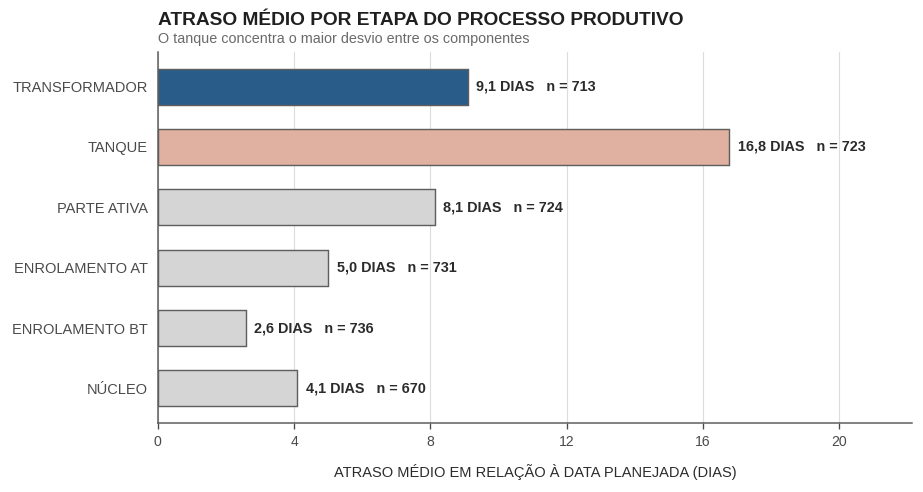


6. SINCRONISMO DA CADEIA NO INSTANTE DO PLANEJAMENTO
  Tanque (caldeiraria)       pronto:  -2.2 d   não pronto:  12.2 d   diferença: +14.5 d
  Núcleo                     pronto:   7.7 d   não pronto:  14.5 d   diferença:  +6.8 d
  Enrolamento BT             pronto:   6.9 d   não pronto:  20.5 d   diferença: +13.6 d
  Enrolamento AT             pronto:   5.1 d   não pronto:  15.8 d   diferença: +10.6 d
  Montagem da parte ativa    pronto:   1.5 d   não pronto:  13.6 d   diferença: +12.1 d


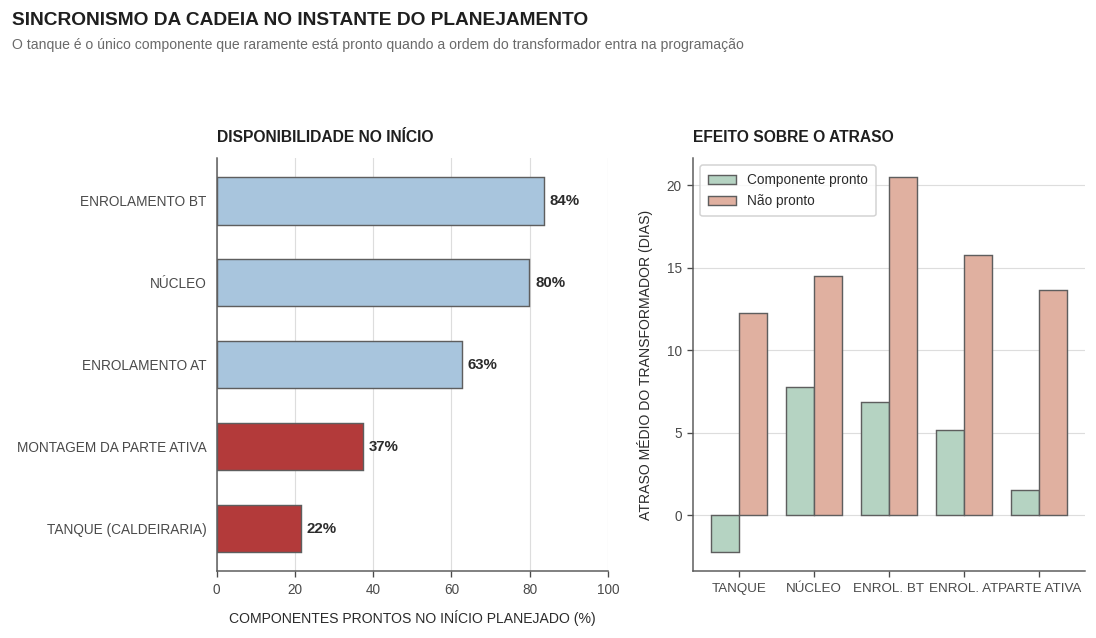


5c. CONVERGENCIA DA CADEIA


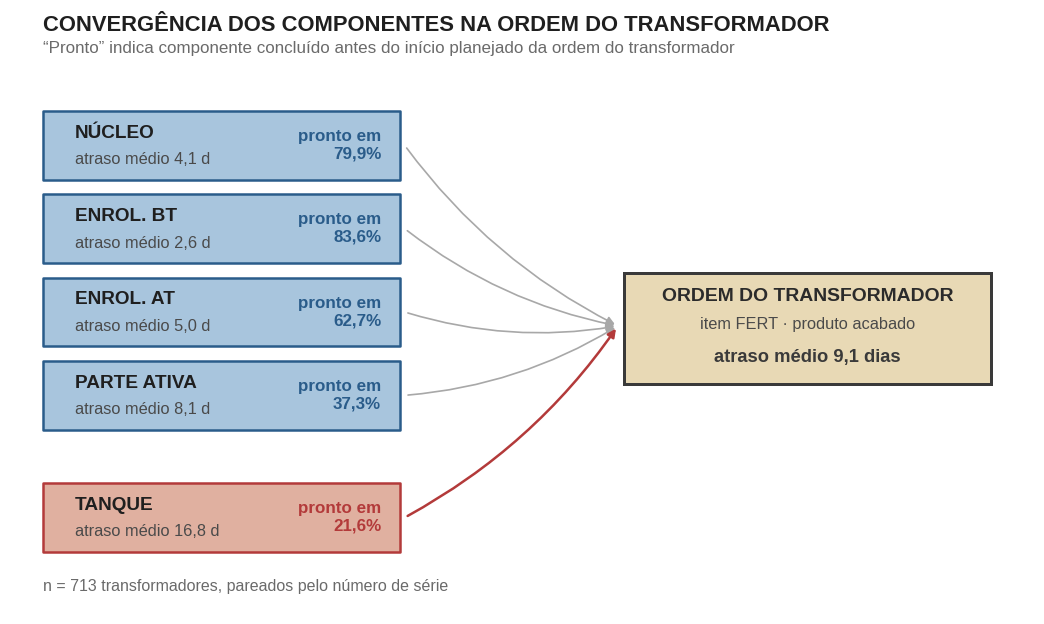


5b. NAO ESTACIONARIEDADE E DISTRIBUICAO DA RESPOSTA
meses com 10 ou mais transformadores: 14
maior media mensal: 19.5 dias (2026-07)
menor media mensal: -3.5 dias (2026-04)
amplitude da oscilacao: 23.0 dias
adiantados 22.0% | no prazo exato 15.0% | atrasados 63.0%


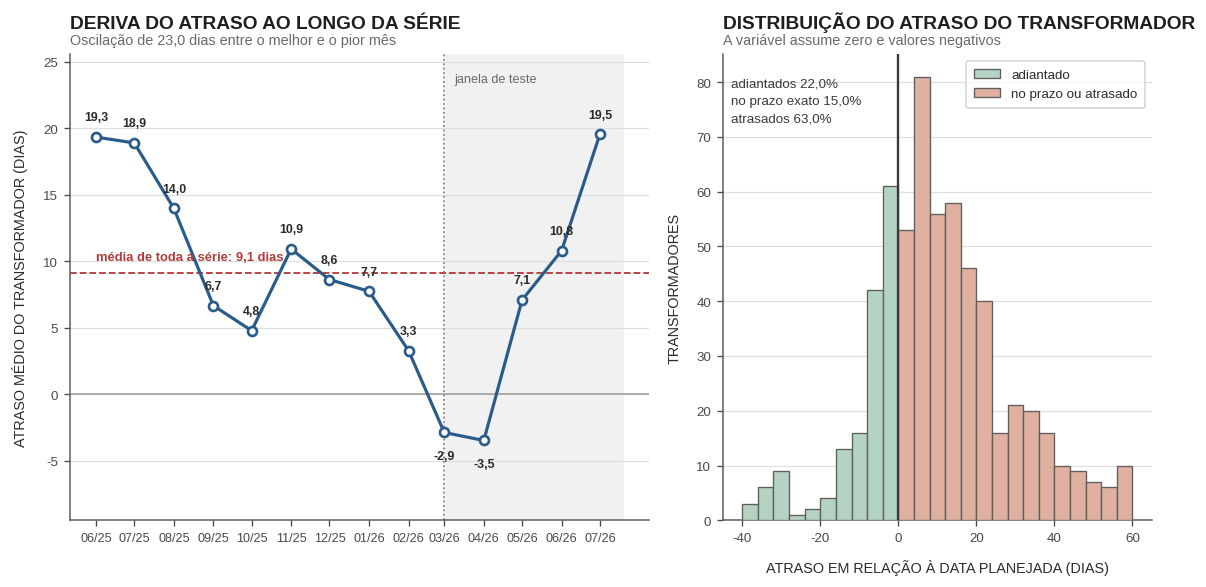


7. INFLUENCIA DA GEOMETRIA DO TANQUE
lead time medio (dias):
TIPO_TANQUE     CORRUGADO  OBLONGO  PEDESTAL
faixa                                       
ATÉ 500               6.0     21.1      10.0
501 A 1.000           8.5     19.3      11.3
1.001 A 2.000         7.2     20.6      18.3
ACIMA DE 2.000       10.9     25.3       4.3

n:
TIPO_TANQUE     CORRUGADO  OBLONGO  PEDESTAL
faixa                                       
ATÉ 500                66       17        69
501 A 1.000           142       27         9
1.001 A 2.000         131       65        10
ACIMA DE 2.000         46       34         3

razao OBLONGO / CORRUGADO:
faixa
ATÉ 500           3.50
501 A 1.000       2.28
1.001 A 2.000     2.85
ACIMA DE 2.000    2.33


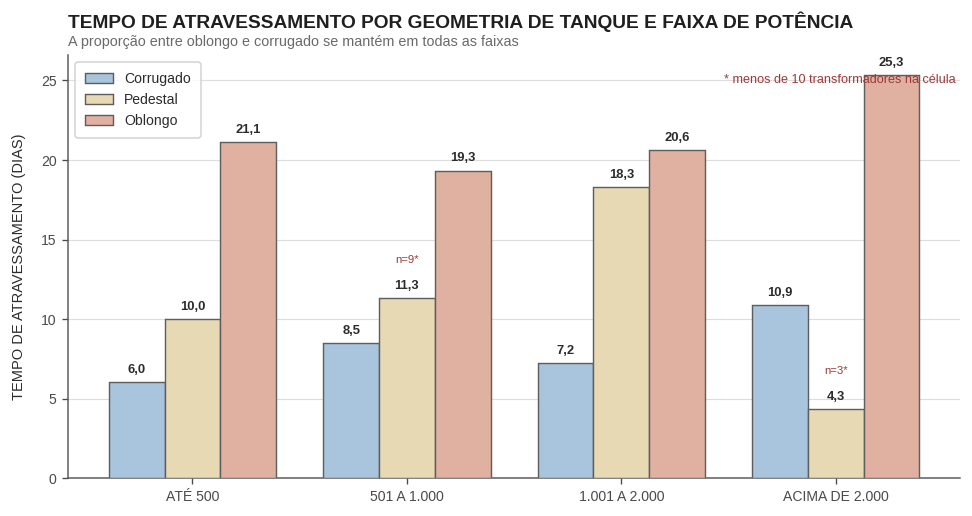

In [10]:
descritiva_cadeia()
grafico_sincronismo()
grafico_cadeia()
grafico_temporal()
grafico_geometria()


## 6. Definição dos modelos e das métricas

O script compara quatro modelos de regressão e quatro classificadores. Nesta célula são definidos os modelos, as grades de parâmetros, os cálculos e os gráficos; o treinamento ocorre nas células seguintes.


In [11]:
# =============================================================================
# 8. MODELAGEM PREDITIVA
# =============================================================================
def pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("esc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT)])


REG = {
    "Random Forest": (RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
                      {"m__n_estimators": [300], "m__max_depth": [6, 10, None],
                       "m__min_samples_leaf": [1, 4, 8]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=SEMENTE),
                          {"m__n_estimators": [200, 400],
                           "m__learning_rate": [0.03, 0.08],
                           "m__max_depth": [2, 3]}),
    "Elastic Net": (ElasticNet(random_state=SEMENTE, max_iter=20000),
                    {"m__alpha": [0.05, 0.1, 0.5, 1.0, 3.0],
                     "m__l1_ratio": [0.1, 0.5, 0.9]}),
    "Rede neural": (MLPRegressor(random_state=SEMENTE, max_iter=3000,
                                 early_stopping=True, n_iter_no_change=30),
                    {"m__hidden_layer_sizes": [(32,), (64, 32), (32, 16)],
                     "m__alpha": [0.001, 0.01, 0.1]}),
}

CLF = {
    "Random Forest": (RandomForestClassifier(random_state=SEMENTE, n_jobs=-1,
                                             class_weight="balanced"),
                      {"m__n_estimators": [300], "m__max_depth": [6, 10, None],
                       "m__min_samples_leaf": [1, 4, 8]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEMENTE),
                          {"m__n_estimators": [200, 400],
                           "m__learning_rate": [0.03, 0.08],
                           "m__max_depth": [2, 3]}),
    "Regressão logística": (LogisticRegression(random_state=SEMENTE, max_iter=5000,
                                               penalty="elasticnet", solver="saga"),
                            {"m__C": [0.1, 1.0, 10.0],
                             "m__l1_ratio": [0.1, 0.5, 0.9]}),
    "Rede neural": (MLPClassifier(random_state=SEMENTE, max_iter=3000,
                                  early_stopping=True, n_iter_no_change=30),
                    {"m__hidden_layer_sizes": [(32,), (64, 32)],
                     "m__alpha": [0.01, 0.1]}),
}


def detalhe(yv, p):
    e = np.abs(np.asarray(yv) - np.asarray(p))
    return {"MAE": float(mean_absolute_error(yv, p)),
            "RMSE": float(np.sqrt(mean_squared_error(yv, p))),
            "R2": float(r2_score(yv, p)),
            "d5": float(np.mean(e <= 5) * 100),
            "d7": float(np.mean(e <= 7) * 100),
            "d10": float(np.mean(e <= 10) * 100)}


def comparar_modelos():
    linha("8. REGRESSAO DO ATRASO DO TRANSFORMADOR")
    print(f"amostra: {len(dm)} transformadores | atraso médio {y.mean():.2f} dias")

    cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
    RES["cv"] = {}
    RES["hiper"] = {}
    print("\nProtocolo 1 — validação cruzada em cinco partições:")
    for nome, (est, grade) in REG.items():
        gs = GridSearchCV(Pipeline([("pre", pre()), ("m", est)]), grade, cv=cv,
                          scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(X, y)
        p = cross_val_predict(gs.best_estimator_, X, y, cv=cv, n_jobs=-1)
        RES["cv"][nome] = detalhe(y, p)
        RES["hiper"][nome] = {k.replace("m__", ""): v
                              for k, v in gs.best_params_.items()}
        r = RES["cv"][nome]
        print(f"   {nome:20s} MAE={r['MAE']:5.2f}  RMSE={r['RMSE']:6.2f}  "
              f"R2={r['R2']:+.3f}")
    RES["cv"]["Linha de base"] = detalhe(y, np.full(len(y), y.mean()))
    r = RES["cv"]["Linha de base"]
    print(f"   {'Linha de base':20s} MAE={r['MAE']:5.2f}  RMSE={r['RMSE']:6.2f}  "
          f"R2={r['R2']:+.3f}")
    print("\nhiperparâmetros selecionados:")
    for n_, h in RES["hiper"].items():
        print(f"   {n_:20s} {h}")

    print(f"\nProtocolo 2 — validação temporal, corte {CORTE.date()} "
          f"(treino {int(tr.sum())}, teste {int(te.sum())}):")
    RES["temporal"] = {}
    for nome, (est, grade) in REG.items():
        gs = GridSearchCV(Pipeline([("pre", pre()), ("m", est)]), grade, cv=cv,
                          scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(X[tr], y[tr])
        RES["temporal"][nome] = detalhe(y[te], gs.best_estimator_.predict(X[te]))
        r = RES["temporal"][nome]
        print(f"   {nome:20s} MAE={r['MAE']:5.2f}  R2={r['R2']:+.3f}  "
              f"±5d={r['d5']:4.1f}%  ±10d={r['d10']:4.1f}%")
    RES["temporal"]["Linha de base"] = detalhe(
        y[te], np.full(int(te.sum()), y[tr].mean()))
    r = RES["temporal"]["Linha de base"]
    print(f"   {'Linha de base':20s} MAE={r['MAE']:5.2f}  R2={r['R2']:+.3f}  "
          f"±5d={r['d5']:4.1f}%  ±10d={r['d10']:4.1f}%")

    # Por que o erro percentual nao se aplica a esta variavel
    print("\n" + "-" * 78)
    print("ADEQUACAO DO ERRO PERCENTUAL (MAPE) A VARIAVEL DE ATRASO")
    print("-" * 78)
    RES["mape"] = {"zero": float((y == 0).mean() * 100),
                   "ate2": float((y.abs() <= 2).mean() * 100),
                   "neg": float((y < 0).mean() * 100)}
    print(f"   atraso exatamente zero : {int((y==0).sum()):3d} "
          f"({RES['mape']['zero']:.1f}%)  -> métrica indefinida")
    print(f"   |atraso| <= 2 dias     : {int((y.abs()<=2).sum()):3d} "
          f"({RES['mape']['ate2']:.1f}%)  -> percentual explode")
    print(f"   atraso negativo        : {int((y<0).sum()):3d} "
          f"({RES['mape']['neg']:.1f}%)  -> percentual sem significado")

    grafico_modelos()


def grafico_modelos():
    ordem = ["Linha de base", "Elastic Net", "Rede neural",
             "Gradient Boosting", "Random Forest"]
    a = [RES["cv"][m]["MAE"] for m in ordem]
    b = [RES["temporal"][m]["MAE"] for m in ordem]
    ys = np.arange(len(ordem)); h = 0.37
    fig, ax = plt.subplots(figsize=(7.8, 4.4))
    b1 = ax.barh(ys + h/2, a, h, color=PASTEL["azul"], edgecolor="#5E5E5E",
                 linewidth=0.85, zorder=3, label="Validação cruzada em 5 partições")
    b2 = ax.barh(ys - h/2, b, h, color=PASTEL["terracota"], edgecolor="#5E5E5E",
                 linewidth=0.85, zorder=3, label="Validação temporal")
    for barras, vals in ((b1, a), (b2, b)):
        for bb, v in zip(barras, vals):
            ax.text(v + 0.16, bb.get_y() + bb.get_height()/2, virg(v, 2),
                    va="center", ha="left", fontsize=8.6, fontweight="bold")
    limpa(ax, "x")
    ax.set_yticks(ys); ax.set_yticklabels([m.upper() for m in ordem], fontsize=8.8)
    ax.set_xlabel("ERRO ABSOLUTO MÉDIO (DIAS)", fontsize=9, labelpad=9)
    ax.set_xlim(0, max(a + b) * 1.16)
    ticks_inteiros(ax, "x", 7); eixo_br(ax, "x", 0)
    ax.tick_params(axis="x", labelsize=8.6); ax.tick_params(axis="y", length=0, pad=6)
    leg = ax.legend(frameon=True, fontsize=8.5, loc="upper center",
                    bbox_to_anchor=(0.5, -0.155), ncol=2, edgecolor="#C8C8C8",
                    borderpad=0.7)
    leg.get_frame().set_linewidth(0.9)
    titulo(ax, "Erro de previsão dos quatro modelos sob dois protocolos",
           "Menor é melhor · todos superam a linha de base nos dois protocolos")
    plt.tight_layout(); plt.savefig(f"{SAIDA}/fig_modelos.png", bbox_inches="tight")
    plt.show()


def classificar_risco():
    linha("9. CLASSIFICACAO DO RISCO DE ATRASO")
    print(f"prevalência de atraso — amostra {yc.mean()*100:.1f}% | "
          f"janela de teste {yc[te].mean()*100:.1f}%\n")
    cvs = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
    RES["clf"] = {}
    for nome, (est, grade) in CLF.items():
        gs = GridSearchCV(Pipeline([("pre", pre()), ("m", est)]), grade, cv=cvs,
                          scoring="f1", n_jobs=-1)
        gs.fit(X[tr], yc[tr])
        pv = gs.best_estimator_.predict(X[te])
        pp = gs.best_estimator_.predict_proba(X[te])[:, 1]
        cm = confusion_matrix(yc[te], pv)
        RES["clf"][nome] = {
            "matriz": cm.tolist(),
            "acuracia": float(accuracy_score(yc[te], pv)),
            "precisao": float(precision_score(yc[te], pv, zero_division=0)),
            "revocacao": float(recall_score(yc[te], pv, zero_division=0)),
            "f1": float(f1_score(yc[te], pv, zero_division=0)),
            "auc": float(roc_auc_score(yc[te], pp)),
            "bal_acc": float(balanced_accuracy_score(yc[te], pv)),
            "mcc": float(matthews_corrcoef(yc[te], pv))}
        r = RES["clf"][nome]
        print(f"   {nome:21s} acc={r['acuracia']*100:5.1f}%  prec={r['precisao']*100:5.1f}%"
              f"  rev={r['revocacao']*100:5.1f}%  F1={r['f1']:.3f}  AUC={r['auc']:.3f}")
        print(f"   {'':21s} bal_acc={r['bal_acc']:.3f}  MCC={r['mcc']:+.3f}   "
              f"[[VN={cm[0,0]:3d} FP={cm[0,1]:3d}] [FN={cm[1,0]:3d} VP={cm[1,1]:3d}]]")
    tv = np.ones(int(te.sum()), dtype=int)
    RES["clf"]["Trivial"] = {
        "acuracia": float(accuracy_score(yc[te], tv)),
        "precisao": float(precision_score(yc[te], tv, zero_division=0)),
        "revocacao": 1.0,
        "f1": float(f1_score(yc[te], tv, zero_division=0)),
        "bal_acc": 0.5, "mcc": 0.0}
    r = RES["clf"]["Trivial"]
    print(f"\n   {'Trivial (tudo atrasa)':21s} acc={r['acuracia']*100:5.1f}%  "
          f"F1={r['f1']:.3f}  bal_acc=0,500  MCC=+0,000")
    grafico_confusao()


def grafico_confusao():
    nomes = [n for n in RES["clf"] if n != "Trivial"]
    fig, axes = plt.subplots(2, 2, figsize=(7.9, 6.6))
    for ax, n in zip(axes.ravel(), nomes):
        cm = np.array(RES["clf"][n]["matriz"])
        ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues",
                  vmin=0, vmax=1, alpha=0.78)
        for i in range(2):
            for j in range(2):
                frac = cm[i, j] / cm[i].sum()
                ax.text(j, i, f"{cm[i,j]}\n{virg(frac*100,1)}%", ha="center",
                        va="center", fontsize=10.5, fontweight="bold",
                        color="white" if frac > 0.55 else "#1F1F1F")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["PREVISTO\nNO PRAZO", "PREVISTO\nATRASADO"], fontsize=7.8)
        ax.set_yticklabels(["REAL\nNO PRAZO", "REAL\nATRASADO"], fontsize=7.8)
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_edgecolor("#9A9A9A"); s.set_linewidth(0.9)
        r = RES["clf"][n]
        ax.set_title(f"{n.upper()}\nacurácia {virg(r['acuracia']*100,1)}%  ·  "
                     f"F1 {virg(r['f1'],3)}  ·  MCC {virg(r['mcc'],3)}",
                     fontsize=8.8, fontweight="bold", color="#1F1F1F", pad=9)
    fig.suptitle("MATRIZES DE CONFUSÃO DOS QUATRO CLASSIFICADORES",
                 fontsize=11.5, fontweight="bold", color="#1F1F1F", y=1.012)
    fig.text(0.5, 0.978, f"Validação temporal · {int(te.sum())} transformadores "
             f"de teste · prevalência real de atraso {virg(yc[te].mean()*100,1)}%",
             ha="center", fontsize=8.4, color="#6A6A6A")
    plt.tight_layout(rect=[0, 0, 1, 0.955])
    plt.savefig(f"{SAIDA}/fig_confusao.png", bbox_inches="tight")
    plt.show()


def importancia_variaveis():
    linha("10. IMPORTANCIA DAS VARIAVEIS")
    mod = Pipeline([("pre", pre()),
                    ("m", RandomForestRegressor(random_state=SEMENTE,
                                                n_estimators=300,
                                                min_samples_leaf=2, n_jobs=-1))])
    mod.fit(X[tr], y[tr])
    imp = permutation_importance(mod, X[te], y[te], n_repeats=30,
                                 random_state=SEMENTE,
                                 scoring="neg_mean_absolute_error")
    r = (pd.DataFrame({"variavel": PRED, "importancia": imp.importances_mean,
                       "dp": imp.importances_std})
         .sort_values("importancia", ascending=False))
    print(r.head(12).to_string(index=False))
    RES["importancia"] = r.head(12).to_dict("records")

    ROT = {"TIPO_TANQUE": "GEOMETRIA DO TANQUE", "lead_plan": "LEAD TIME PLANEJADO",
           "kVA": "POTÊNCIA NOMINAL", "PESO": "PESO DO TANQUE",
           "carga_semanal": "CARGA SEMANAL", "CAMADAS": "CAMADAS DE TINTA",
           "CAIXA_BUCHA": "CAIXA DE BUCHA", "PLANO_PINTURA": "PLANO DE PINTURA"}
    for k, v in CURTO.items():
        ROT[f"concluido_{k}"] = f"{v} PRONTO"
        ROT[f"folga_plan_{k}"] = f"FOLGA PLAN. {v}"
        ROT[f"atraso_{k}"] = f"ATRASO {v}"
        ROT[f"lead_plan_{k}"] = f"LEAD PLAN. {v}"

    top = r.head(10).sort_values("importancia")
    cores = [FORTE["verde"] if v.startswith(("concluido_", "folga_plan_", "atraso_"))
             else PASTEL["azul"] for v in top["variavel"]]
    fig, ax = plt.subplots(figsize=(7.8, 4.6))
    bs = ax.barh([ROT.get(v, v) for v in top["variavel"]], top["importancia"],
                 xerr=top["dp"], color=cores, edgecolor="#5E5E5E", linewidth=0.85,
                 height=0.6, zorder=3,
                 error_kw=dict(ecolor="#7A7A7A", lw=0.9, capsize=2.5))
    for b, v, dp in zip(bs, top["importancia"], top["dp"]):
        ax.text(v + dp + 0.04, b.get_y() + b.get_height()/2, virg(v, 2),
                va="center", ha="left", fontsize=8.4, fontweight="bold")
    limpa(ax, "x")
    ax.set_xlabel("AUMENTO DO ERRO ABSOLUTO MÉDIO AO EMBARALHAR A VARIÁVEL (DIAS)",
                  fontsize=8.5, labelpad=9)
    ax.tick_params(axis="y", labelsize=8.2, length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8.2); eixo_br(ax, "x", 1)
    ax.set_xlim(0, max(top["importancia"] + top["dp"]) * 1.28)
    ax.text(0.995, 0.06, "Em verde, as variáveis de sincronismo da cadeia",
            transform=ax.transAxes, ha="right", fontsize=7.8, color=FORTE["verde"])
    titulo(ax, "Importância das variáveis por permutação",
           "Random Forest avaliado na janela temporal de teste")
    plt.tight_layout(); plt.savefig(f"{SAIDA}/fig_importancia.png", bbox_inches="tight")
    plt.show()


## 7. Regressão: previsão do atraso em dias

Esta é normalmente uma das etapas mais demoradas. São executadas as validações cruzada e temporal e gerado o gráfico de comparação.


In [ ]:
comparar_modelos()



8. REGRESSAO DO ATRASO DO TRANSFORMADOR
amostra: 619 transformadores | atraso médio 8.30 dias

Protocolo 1 — validação cruzada em cinco partições:
   Random Forest        MAE= 8.24  RMSE= 12.15  R2=+0.499
   Gradient Boosting    MAE= 8.53  RMSE= 12.39  R2=+0.479
   Elastic Net          MAE= 9.58  RMSE= 13.35  R2=+0.395
   Rede neural          MAE= 9.40  RMSE= 13.20  R2=+0.409
   Linha de base        MAE=12.43  RMSE= 17.17  R2=+0.000

hiperparâmetros selecionados:
   Random Forest        {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
   Gradient Boosting    {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400}
   Elastic Net          {'alpha': 0.5, 'l1_ratio': 0.9}
   Rede neural          {'alpha': 0.001, 'hidden_layer_sizes': (32,)}

Protocolo 2 — validação temporal, corte 2026-03-01 (treino 376, teste 243):


## 8. Classificação: risco de atraso

São apresentadas as métricas e as matrizes de confusão para os quatro classificadores.


In [ ]:
classificar_risco()


## 9. Importância das variáveis

O código aplica importância por permutação ao Random Forest de regressão, avaliado no conjunto temporal de teste.


In [ ]:
importancia_variaveis()


## 10. Ferramenta de apoio à decisão

A função abaixo define a ferramenta e seu teste retrospectivo. A execução vem na célula seguinte.


In [ ]:
# =============================================================================
# 11. FERRAMENTA DE APOIO A DECISAO DO PCP
#
#  Recebe uma ordem de transformador no momento em que ela entra na
#  programacao e devolve tres estimativas:
#     1) probabilidade de atraso (%)
#     2) atraso em dias, com faixa de incerteza
#     3) data prevista de conclusao
# =============================================================================
JANELA = 240        # dias de historico usados no treino da janela movel
JANELA_AJUSTE = 90  # dias finais usados para estimar a correcao de nivel
LIMIAR = 0.50       # ponto de alerta; revisto pelo backtest
BANDA = (0.40, 0.70)


def _reg():
    return Pipeline([("pre", pre()),
                     ("m", RandomForestRegressor(random_state=SEMENTE,
                                                 n_estimators=300,
                                                 min_samples_leaf=2, n_jobs=-1))])


def _clf():
    b = Pipeline([("pre", pre()),
                  ("m", RandomForestClassifier(random_state=SEMENTE,
                                               n_estimators=300, max_depth=10,
                                               min_samples_leaf=4, n_jobs=-1))])
    # calibracao isotonica: converte o escore em probabilidade com significado
    # frequentista ("de cada 100 ordens com 70%, cerca de 70 atrasam")
    return CalibratedClassifierCV(b, method="isotonic", cv=5)


def treinar(d, origem):
    """Treina com os transformadores concluidos da janela anterior a origem.

    O processo nao e estacionario: a prevalencia de atraso no treino cai de 69%
    para 49% ao longo do periodo. Um modelo ajustado sobre um trecho pior do
    historico superestima o atraso no presente. A correcao de nivel e estimada
    sobre os transformadores concluidos mais recentes da propria janela de
    treino - nunca sobre os dados de teste.
    """
    ini = origem - pd.Timedelta(days=JANELA)
    t = d[(d.GSTRP >= ini) & (d.GSTRP < origem)]
    if len(t) < 100:
        t = d[d.GSTRP < origem]
    Xt, yt = t[PRED], t["atraso"].astype(float)
    ytc = (yt > 0).astype(int)
    reg = _reg().fit(Xt, yt)

    recente = t[t.GSTRP >= origem - pd.Timedelta(days=JANELA_AJUSTE)]
    desvio = 0.0
    if len(recente) >= 40:
        desvio = float(np.mean(reg.predict(recente[PRED])
                               - recente["atraso"].astype(float)))
    return {"reg": reg, "clf": _clf().fit(Xt, ytc), "desvio": desvio,
            "n": len(t), "prev": float(ytc.mean())}


def prever(mod, d):
    Xa = d[PRED]
    prob = mod["clf"].predict_proba(Xa)[:, 1]
    dias = mod["reg"].predict(Xa) - mod.get("desvio", 0.0)
    Xt = mod["reg"].named_steps["pre"].transform(Xa)
    arv = np.stack([a.predict(Xt) for a in mod["reg"].named_steps["m"].estimators_])
    lo, hi = np.percentile(arv, [10, 90], axis=0) - mod.get("desvio", 0.0)
    out = pd.DataFrame({
        "NS": d["NS"].values, "AUFNR": d["AUFNR"].values, "CP": d["CP"].values,
        "material": d["MATXT"].values, "TIPO_TANQUE": d["TIPO_TANQUE"].values,
        "kVA": d["kVA"].values,
        "fim_planejado": pd.to_datetime(d["GLTRP"]).values,
        "prob_atraso": prob, "dias_estimados": dias,
        "dias_min": lo, "dias_max": hi})
    out["data_prevista"] = (out["fim_planejado"]
                            + pd.to_timedelta(np.round(out["dias_estimados"]),
                                              unit="D"))
    out["risco"] = pd.cut(out["prob_atraso"], [-.01, BANDA[0], BANDA[1], 1.01],
                          labels=["BAIXO", "MEDIO", "ALTO"])
    if len(out) > 1:
        rk = (out["prob_atraso"].rank(pct=True)
              + out["dias_estimados"].rank(pct=True)) / 2
        out["prioridade"] = (rk * 100).round(0).astype(int)
    else:
        out["prioridade"] = 100
    return out


def ficha(d):
    dias = int(round(d["dias_estimados"]))
    lo, hi = int(round(d["dias_min"])), int(round(d["dias_max"]))
    if dias > 0:
        txt = f"{dias} dias (faixa de {lo} a {hi})"
    elif dias == 0:
        txt = f"nenhum (faixa de {lo} a {hi} dias)"
    else:
        txt = (f"nenhum; conclusão prevista {abs(dias)} dias antes do prazo "
               f"(faixa de {lo} a {hi})")
    return (
        f"\nORDEM DE PRODUÇÃO {int(d['AUFNR'])}   (nº de série {int(d['NS'])})\n"
        f"  Produto ..................... {str(d['material'])[:46]}\n"
        f"  Geometria do tanque ......... {str(d['TIPO_TANQUE']).title()}  |  "
        f"{d['kVA']:.0f} kVA\n"
        f"  Fim planejado no sistema .... "
        f"{pd.Timestamp(d['fim_planejado']).strftime('%d/%m/%Y')}\n"
        f"  ------------------------------------------------------------\n"
        f"  Probabilidade de atraso ..... {d['prob_atraso']*100:.0f}%   "
        f"[{d['risco']}]\n"
        f"  Atraso estimado ............. {txt}\n"
        f"  Conclusão prevista .......... "
        f"{pd.Timestamp(d['data_prevista']).strftime('%d/%m/%Y')}\n"
        f"  Prioridade na carteira ...... {d['prioridade']}º percentil\n")


def ferramenta():
    linha("11. FERRAMENTA DE APOIO A DECISAO — TESTE RETROSPECTIVO")
    d = dm.sort_values("GSTRP")
    meses = pd.period_range("2026-03", "2026-07", freq="M")
    R = []
    for m in meses:
        o, f = m.to_timestamp(), (m + 1).to_timestamp()
        teste = d[(d.GSTRP >= o) & (d.GSTRP < f)]
        if len(teste) < 15:
            continue
        mod = treinar(d, o)
        r = prever(mod, teste)
        r["real_dias"] = teste["atraso"].astype(float).values
        r["real_fim"] = pd.to_datetime(teste["GLTRI"]).values
        print(f"   {m}  treino={mod['n']:3d}  teste={len(teste):3d}  "
              f"prevalência no treino={mod['prev']*100:.1f}%  "
              f"correção de nível={mod['desvio']:+.2f}d")
        R.append(r)
    r = pd.concat(R, ignore_index=True)
    yv = r["real_dias"].values
    yvc = (yv > 0).astype(int)
    e = np.abs(yv - r["dias_estimados"].values)

    # limiar que maximiza a medida F1 no proprio backtest
    grade = np.arange(0.30, 0.86, 0.01)
    f1s = [f1_score(yvc, (r["prob_atraso"] >= t).astype(int), zero_division=0)
           for t in grade]
    lim = float(grade[int(np.argmax(f1s))])
    pv = (r["prob_atraso"] >= lim).astype(int)
    cm = confusion_matrix(yvc, pv)
    tv = np.ones(len(yvc), dtype=int)

    RES["ferramenta"] = {
        "n": int(len(r)), "limiar": lim,
        "auc": float(roc_auc_score(yvc, r["prob_atraso"])),
        "brier": float(brier_score_loss(yvc, r["prob_atraso"])),
        "acuracia": float(accuracy_score(yvc, pv)),
        "precisao": float(precision_score(yvc, pv, zero_division=0)),
        "revocacao": float(recall_score(yvc, pv, zero_division=0)),
        "f1": float(f1_score(yvc, pv, zero_division=0)),
        "bal_acc": float(balanced_accuracy_score(yvc, pv)),
        "mcc": float(matthews_corrcoef(yvc, pv)),
        "matriz": cm.tolist(),
        "acuracia_trivial": float(accuracy_score(yvc, tv)),
        "f1_trivial": float(f1_score(yvc, tv, zero_division=0)),
        "mae": float(mean_absolute_error(yv, r["dias_estimados"])),
        "mae_base": float(mean_absolute_error(yv, np.full(len(yv), yv.mean()))),
        "d5": float(np.mean(e <= 5) * 100), "d10": float(np.mean(e <= 10) * 100),
        "cobertura": float(((yv >= r["dias_min"]) & (yv <= r["dias_max"])).mean() * 100),
    }
    ed = (r["data_prevista"].values - r["real_fim"].values) / np.timedelta64(1, "D")
    es = (r["fim_planejado"].values - r["real_fim"].values) / np.timedelta64(1, "D")
    RES["ferramenta"].update({
        "data_mediana": float(np.median(np.abs(ed))),
        "data_mediana_sap": float(np.median(np.abs(es))),
        "data_d7": float(np.mean(np.abs(ed) <= 7) * 100),
        "data_d7_sap": float(np.mean(np.abs(es) <= 7) * 100)})
    rr, pp_ = stats.pearsonr(r["prob_atraso"], r["dias_estimados"])
    disc = ((r["prob_atraso"] >= lim) & (r["dias_estimados"] <= 0)) | \
           ((r["prob_atraso"] < 0.33) & (r["dias_estimados"] > 10))
    RES["ferramenta"].update({"corr": float(rr), "p_corr": float(pp_),
                              "disc": float(disc.mean() * 100)})

    f = RES["ferramenta"]
    print(f"\nagregado: {f['n']} transformadores | prevalência real "
          f"{yvc.mean()*100:.1f}%\n")
    print("SAÍDA 1 — PROBABILIDADE DE ATRASO")
    print(f"   AUC {f['auc']:.3f} | Brier {f['brier']:.4f} | limiar escolhido {lim:.2f}")
    print(f"   acurácia {f['acuracia']*100:.1f}%  precisão {f['precisao']*100:.1f}%  "
          f"revocação {f['revocacao']*100:.1f}%  F1 {f['f1']:.3f}")
    print(f"   acurácia balanceada {f['bal_acc']:.3f} | MCC {f['mcc']:+.3f}")
    print(f"   matriz [[VN={cm[0,0]:3d} FP={cm[0,1]:3d}] [FN={cm[1,0]:3d} VP={cm[1,1]:3d}]]")
    print(f"   trivial: acurácia {f['acuracia_trivial']*100:.1f}%  "
          f"F1 {f['f1_trivial']:.3f}  MCC +0,000")
    print("\nSAÍDA 2 — ATRASO ESTIMADO EM DIAS")
    print(f"   MAE {f['mae']:.2f} dias | linha de base {f['mae_base']:.2f} | "
          f"±5d {f['d5']:.1f}% | ±10d {f['d10']:.1f}%")
    print(f"   faixa p10-p90 contém o valor real em {f['cobertura']:.1f}% dos casos")
    print("\nSAÍDA 3 — DATA PREVISTA DE CONCLUSÃO")
    print(f"   ferramenta : erro mediano {f['data_mediana']:.1f} dias | "
          f"±7 dias {f['data_d7']:.1f}%")
    print(f"   data do SAP: erro mediano {f['data_mediana_sap']:.1f} dias | "
          f"±7 dias {f['data_d7_sap']:.1f}%")
    print("\nCONSISTÊNCIA ENTRE AS DUAS SAÍDAS")
    print(f"   probabilidade x dias: r = {rr:.3f} (p = {pp_:.1e})")
    print(f"   saídas contraditórias: {f['disc']:.1f}%")

    # ---- estratificacao de risco: e aqui que a ferramenta entrega valor ----
    print("\nESTRATIFICACAO DA CARTEIRA POR FAIXA DE RISCO")
    print(f"   {'faixa':8s} {'n':>4s} {'atrasaram':>10s} {'atraso medio':>13s}")
    RES["faixas"] = {}
    for fx in ["BAIXO", "MEDIO", "ALTO"]:
        d_ = r[r.risco == fx]
        if not len(d_):
            continue
        taxa = float((d_["real_dias"] > 0).mean() * 100)
        med = float(d_["real_dias"].mean())
        RES["faixas"][fx] = {"n": int(len(d_)), "taxa": taxa, "media": med}
        print(f"   {fx:8s} {len(d_):4d} {taxa:9.1f}% {med:12.1f} d")

    grafico_ferramenta(r, yvc, ed, es)
    r.to_csv(f"{SAIDA}/previsao_transformadores.csv", index=False)
    print(f"\narquivo gravado: {SAIDA}/previsao_transformadores.csv")

    print("\n" + "-" * 78)
    print("EXEMPLO — ORDEM DE TRANSFORMADOR DE MAIOR PRIORIDADE")
    print("-" * 78)
    rp = r.sort_values("prioridade", ascending=False)
    print(ficha(rp.iloc[0]))
    ex = rp.iloc[0]
    RES["exemplo"] = {k: (str(ex[k]) if not isinstance(ex[k], (int, float, np.number))
                          else float(ex[k]))
                      for k in ["AUFNR", "NS", "material", "TIPO_TANQUE", "kVA",
                                "prob_atraso", "dias_estimados", "dias_min",
                                "dias_max", "prioridade"]}
    RES["exemplo"]["fim_planejado"] = pd.Timestamp(ex["fim_planejado"]).strftime("%d/%m/%Y")
    RES["exemplo"]["data_prevista"] = pd.Timestamp(ex["data_prevista"]).strftime("%d/%m/%Y")
    return r


def grafico_ferramenta(r, yvc, ed, es):
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.9))
    ax = axes[0]
    dd = pd.DataFrame({"p": r["prob_atraso"], "y": yvc})
    g = dd.groupby(pd.cut(dd.p, [0, .2, .4, .6, .8, 1.0]), observed=True).agg(
        prev=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    g = g[g.n >= 8]
    ax.plot([0, 1], [0, 1], color="#AFAFAF", lw=1.2, ls="--", zorder=2,
            label="Calibração perfeita")
    ax.plot(g.prev, g.obs, color=FORTE["azul"], lw=2.2, marker="o", markersize=7,
            markerfacecolor="white", markeredgewidth=1.8, zorder=4,
            label="Ferramenta")
    for _, x in g.iterrows():
        ax.annotate(f"n={int(x.n)}", (x.prev, x.obs), textcoords="offset points",
                    xytext=(0, 13), ha="center", fontsize=7.8, color="#6A6A6A")
    limpa(ax, "both"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("PROBABILIDADE PREVISTA", fontsize=8.6, labelpad=8)
    ax.set_ylabel("FREQUÊNCIA OBSERVADA DE ATRASO", fontsize=8.6, labelpad=8)
    ax.set_xticks(np.arange(0, 1.01, .2)); ax.set_yticks(np.arange(0, 1.01, .2))
    eixo_br(ax, "x", 1); eixo_br(ax, "y", 1); ax.tick_params(labelsize=8.2)
    leg = ax.legend(frameon=True, fontsize=8.3, loc="upper left",
                    edgecolor="#C8C8C8", borderpad=0.6)
    leg.get_frame().set_linewidth(0.9)
    ax.set_title("ADERÊNCIA DA PROBABILIDADE", fontsize=9.4, fontweight="bold",
                 loc="left", color="#1F1F1F", pad=10)

    ax = axes[1]
    lim = np.arange(0, 31)
    ax.plot(lim, [np.mean(np.abs(es) <= k) * 100 for k in lim],
            color=FORTE["grafite"], lw=2.0, ls="--", zorder=3,
            label="Data planejada do SAP")
    ax.plot(lim, [np.mean(np.abs(ed) <= k) * 100 for k in lim],
            color=FORTE["vermelho"], lw=2.4, zorder=4,
            label="Data prevista pela ferramenta")
    ax.axvline(7, color="#BFBFBF", lw=0.9, zorder=1)
    ax.text(7.4, 6, "±7 DIAS", fontsize=7.9, color="#7A7A7A", rotation=90, va="bottom")
    limpa(ax, "both"); ax.set_xlim(0, 30); ax.set_ylim(0, 100)
    ax.set_xlabel("TOLERÂNCIA DE ERRO (DIAS)", fontsize=8.6, labelpad=8)
    ax.set_ylabel("TRANSFORMADORES DENTRO DA TOLERÂNCIA (%)", fontsize=8.6, labelpad=8)
    eixo_br(ax, "y", 0); ax.tick_params(labelsize=8.2)
    leg = ax.legend(frameon=True, fontsize=8.3, loc="lower right",
                    edgecolor="#C8C8C8", borderpad=0.6)
    leg.get_frame().set_linewidth(0.9)
    ax.set_title("PRECISÃO DA DATA DE CONCLUSÃO", fontsize=9.4, fontweight="bold",
                 loc="left", color="#1F1F1F", pad=10)

    fig.suptitle("DESEMPENHO DA FERRAMENTA DE APOIO À DECISÃO",
                 fontsize=11.5, fontweight="bold", color="#1F1F1F", x=0.012,
                 ha="left", y=1.075)
    fig.text(0.012, 1.012, f"Teste retrospectivo com retreinamento mensal · "
             f"{len(r)} transformadores", ha="left", fontsize=8.4, color="#6A6A6A")
    plt.tight_layout(rect=[0, 0, 1, 0.965])
    plt.savefig(f"{SAIDA}/fig_ferramenta.png", bbox_inches="tight")
    plt.show()


In [ ]:
resultado_ferramenta = ferramenta()


## 11. Consultar e salvar os resultados

As tabelas abaixo resumem as métricas produzidas nesta execução. Os arquivos originais de saída são `resultados.json`, `previsao_transformadores.csv` e os gráficos `fig_*.png`.


In [ ]:
print("REGRESSÃO — validação cruzada")
display(pd.DataFrame(RES["cv"]).T.round(3))
print("REGRESSÃO — validação temporal")
display(pd.DataFrame(RES["temporal"]).T.round(3))
print("CLASSIFICAÇÃO — teste temporal")
colunas_clf = ["acuracia", "precisao", "revocacao", "f1", "auc", "bal_acc", "mcc"]
display(pd.DataFrame(RES["clf"]).T.reindex(columns=colunas_clf).round(3))
print("FERRAMENTA — teste retrospectivo")
resumo_ferramenta = RES["ferramenta"].copy()
resumo_ferramenta["p_corr"] = f"{resumo_ferramenta['p_corr']:.2e}"
display(pd.DataFrame.from_dict(resumo_ferramenta, orient="index", columns=["Resultado"]))

with open(os.path.join(SAIDA, "resultados.json"), "w", encoding="utf-8") as arquivo:
    json.dump(RES, arquivo, indent=1, ensure_ascii=False, default=str)
print("Resultados gravados em:", os.path.join(SAIDA, "resultados.json"))


## 12. Conferências metodológicas para discutir no TCC

Estas conferências **não alteram os cálculos originais**. A reprodução dos números, por si só, não confirma que a avaliação representa uma previsão feita em tempo real.

- No corte temporal e na função `treinar`, o script seleciona o histórico pelo **início planejado**, sem exigir que o término real tenha ocorrido antes da data de referência. A tabela abaixo mostra quantos registros requerem verificação.
- No teste da ferramenta, o limiar de classificação é escolhido e avaliado no mesmo conjunto. Além disso, a linha de base `mae_base` usa a média dos atrasos observados nesse próprio conjunto.
- Na validação cruzada de regressão, os hiperparâmetros são escolhidos usando toda a amostra antes de gerar as previsões cruzadas. A avaliação dessa seleção não é aninhada.
- A calibração e a faixa entre os percentis das árvores precisam ser avaliadas empiricamente; não representam garantia automática de probabilidade ou cobertura futura.


In [ ]:
fins_treino = dm.loc[tr, "GLTRI"]
print("Término real posterior à data de corte:", int((fins_treino > CORTE).sum()))
print("Término real na data de corte:", int((fins_treino == CORTE).sum()))
print("Em ou após a data de corte:", int((fins_treino >= CORTE).sum()),
      "de", int(tr.sum()), "ordens no treino")
conferencias = []
for periodo in pd.period_range("2026-03", "2026-07", freq="M"):
    origem = periodo.to_timestamp()
    historico = dm[(dm.GSTRP >= origem - pd.Timedelta(days=JANELA)) & (dm.GSTRP < origem)]
    if len(historico) < 100:
        historico = dm[dm.GSTRP < origem]
    teste_mes = dm[(dm.GSTRP >= origem) & (dm.GSTRP < (periodo + 1).to_timestamp())]
    if len(teste_mes) >= 15:
        conferencias.append({"Mês de teste": str(periodo), "Ordens no treino": len(historico),
                             "Fim após a origem": int((historico.GLTRI > origem).sum()),
                             "Fim na data de origem": int((historico.GLTRI == origem).sum())})
display(pd.DataFrame(conferencias))


## 13. Reunir os arquivos para download

Esta célula inclui apenas as saídas identificadas do estudo no arquivo ZIP; ela não inclui automaticamente as planilhas originais. Se reiniciar o ambiente, execute o notebook novamente para recriar os resultados.


In [ ]:
import hashlib
import zipfile
from pathlib import Path

metadados = {"versoes": versoes_ambiente,
             "sha256_script_adaptado_na_geracao": "3720e9b4484877914e359ba81894550410a5e4fc3ac4e67d2aa9c047702691e5",
             "sha256_planilhas": {}}
for arquivo in [BASE, CTRL]:
    sha = hashlib.sha256()
    with open(arquivo, "rb") as fonte:
        for bloco in iter(lambda: fonte.read(1024 * 1024), b""):
            sha.update(bloco)
    metadados["sha256_planilhas"][os.path.basename(arquivo)] = sha.hexdigest()
with open(os.path.join(SAIDA, "ambiente_execucao.json"), "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, ensure_ascii=False, indent=2)

nomes_saida = ["resultados.json", "previsao_transformadores.csv", "ambiente_execucao.json",
               "fig_etapas.png", "fig_sincronismo.png", "fig_cadeia.png", "fig_temporal.png",
               "fig_geometria.png", "fig_modelos.png", "fig_confusao.png",
               "fig_importancia.png", "fig_ferramenta.png"]
zip_saida = Path(SAIDA) / "resultados_TCC.zip"
with zipfile.ZipFile(zip_saida, "w", compression=zipfile.ZIP_DEFLATED) as pacote:
    for nome in nomes_saida:
        arquivo = Path(SAIDA) / nome
        if arquivo.is_file():
            pacote.write(arquivo, arcname=nome)
        else:
            print("Não encontrado:", nome)
print("Arquivo criado:", zip_saida)
print("Para baixar, execute a próxima célula ou use o painel de arquivos do Colab.")


In [ ]:
# Execute esta célula para baixar o ZIP no Google Colab.
try:
    from google.colab import files
    files.download(str(zip_saida))
except ImportError:
    print("Fora do Colab, acesse o arquivo em:", zip_saida)
